In [ ]:
%pip -q install lpips scikit-image tqdm seaborn

import os, json, random, time, hashlib, shutil, zipfile, statistics
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('Physical GPUs:', tf.config.list_physical_devices('GPU'))
if not tf.config.list_physical_devices('GPU'):
    print('WARNING: GPU not detected. Training and latency testing may be very slow.')

# Mount Drive to access the ZIP and retain results after Colab sessions end.
from google.colab import drive
drive.mount('/content/drive')

TensorFlow: 2.21.0
Physical GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Dataset: use the path from your working Colab configuration.
ZIP_PATH = Path('/content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/5y9wdsg2zt-2.zip')
WORK_DIR = Path('/content/ccwc2027_full_experiment')
DATA_DIR = WORK_DIR / 'dataset_extracted'
IMAGE_DIR = WORK_DIR / 'resized_jpegs'
RESULTS_DIR = Path('/content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results')
for p in (WORK_DIR, DATA_DIR, IMAGE_DIR, RESULTS_DIR):
    p.mkdir(parents=True, exist_ok=True)

# The paper specifies 2,000 maximum epochs and 20-epoch patience.
CNN_MAX_EPOCHS = 2000
SR_MAX_EPOCHS = 2000
EARLY_STOP_PATIENCE = 20
EARLY_STOP_MIN_DELTA = 0.0001  # YOUR REQUEST: minimum absolute validation-loss decrease
CNN_BATCH_SIZE = 32
SR_BATCH_SIZE = 16

# Original piecewise epoch boundary unavailable: 100 is a reconstruction choice.
LR_DROP_EPOCH = 100
LR_INITIAL = 1e-4
LR_FINAL = 1e-5
CLASSIFICATION_THRESHOLD = 0.5
JPEG_QUALITY = 75

RETRAIN_CNN = True
RETRAIN_ESPCNN = True
RUN_LPIPS = True
RUN_TIMING = True
TIMING_REPEATS = 5

if not ZIP_PATH.is_file():
    candidates = sorted(Path('/content/drive/MyDrive').rglob('*.zip'))
    print('ZIP archives found:', *candidates[:30], sep='\n  ')
    raise FileNotFoundError(f'Archive not found: {ZIP_PATH}')
print('Found dataset ZIP:', ZIP_PATH)
print('Archive MB:', round(ZIP_PATH.stat().st_size / 1e6, 1))
print('Results folder:', RESULTS_DIR)
print('Early stopping: val_loss, min_delta=', EARLY_STOP_MIN_DELTA,
      ', patience=', EARLY_STOP_PATIENCE)


Found dataset ZIP: /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/5y9wdsg2zt-2.zip
Archive MB: 240.8
Results folder: /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results
Early stopping: val_loss, min_delta= 0.0001 , patience= 20


In [ ]:
extract_marker = DATA_DIR / '.extraction_complete'
if not extract_marker.exists():
    print('Extracting ZIP to Colab local disk:', DATA_DIR)
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        root = DATA_DIR.resolve()
        for info in z.infolist():
            destination = (DATA_DIR / info.filename).resolve()
            if not destination.is_relative_to(root):
                raise ValueError(f'Unsafe ZIP path: {info.filename}')
        z.extractall(DATA_DIR)
    extract_marker.write_text(str(ZIP_PATH))
else:
    print('Using previously extracted ZIP contents.')

EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp', '.webp'}
def find_class_folders(label):
    folders = [d for d in DATA_DIR.rglob('*') if d.is_dir() and d.name.casefold() == label.casefold()]
    return [d for d in folders if any(p.is_file() and p.suffix.lower() in EXTENSIONS for p in d.rglob('*'))]

# Mendeley ZIP can include a single .rar archive rather than class directories.
if not (find_class_folders('Positive') and find_class_folders('Negative')):
    rar_files = sorted(DATA_DIR.rglob('*.rar'))
    if rar_files:
        import subprocess, shutil
        if shutil.which('unar') is None:
            subprocess.run(['apt-get', '-qq', 'update'], check=True)
            subprocess.run(['apt-get', '-qq', 'install', '-y', 'unar'], check=True)
        for rar_file in rar_files:
            print('Extracting nested RAR:', rar_file.name)
            subprocess.run(['unar', '-quiet', '-force-overwrite', '-output-directory', str(DATA_DIR), str(rar_file)], check=True)

def locate_class_dir(label):
    candidates = find_class_folders(label)
    if len(candidates) != 1:
        raise RuntimeError(f'Expected one {label}/ folder; found {len(candidates)}: {candidates[:8]}')
    return candidates[0]

POS_DIR = locate_class_dir('Positive')
NEG_DIR = locate_class_dir('Negative')
print('Positive:', POS_DIR)
print('Negative:', NEG_DIR)

def list_images(d):
    return sorted([p for p in d.rglob('*') if p.is_file() and p.suffix.lower() in EXTENSIONS],
                  key=lambda p: str(p.relative_to(d)).lower())

positive_all = list_images(POS_DIR)
negative_all = list_images(NEG_DIR)
print('Available positive:', len(positive_all))
print('Available negative:', len(negative_all))
if min(len(positive_all), len(negative_all)) < 5000:
    raise ValueError('Need at least 5,000 images in each class; verify the ZIP file contents.')

Using previously extracted ZIP contents.
Positive: /content/ccwc2027_full_experiment/dataset_extracted/Concrete Crack Images for Classification/Positive
Negative: /content/ccwc2027_full_experiment/dataset_extracted/Concrete Crack Images for Classification/Negative
Available positive: 20000
Available negative: 20000


In [ ]:
rng = np.random.default_rng(SEED)

def select_class(files, cls, label):
    idx = np.sort(rng.choice(len(files), size=5000, replace=False))
    return pd.DataFrame({
        'id': [f'{cls}_{i:05d}' for i in range(5000)],
        'label': label,
        'class_name': cls,
        'original_path': [str(files[j]) for j in idx],
        'original_filename': [files[j].name for j in idx],
    })

positives = select_class(positive_all, 'Positive', 1)
negatives = select_class(negative_all, 'Negative', 0)
manifest = pd.concat([positives, negatives], ignore_index=True)
manifest['lr_path'] = manifest.apply(lambda r: str(IMAGE_DIR / r['class_name'] / 'LR' / (r['id']+'.jpg')), axis=1)
manifest['hr_path'] = manifest.apply(lambda r: str(IMAGE_DIR / 'Positive' / 'HR' / (r['id']+'.jpg')) if r['label']==1 else '', axis=1)
assert len(manifest)==10000 and manifest['id'].is_unique
# Refuse stale cached JPEGs if the selected source files have changed.
old_manifest_path = WORK_DIR / 'cached_selection.csv'
if old_manifest_path.is_file():
    old_manifest = pd.read_csv(old_manifest_path)
    fields = ['id', 'original_path']
    if not old_manifest[fields].equals(manifest[fields]):
        print('Selection changed; deleting stale cached resized JPEGs.')
        shutil.rmtree(IMAGE_DIR, ignore_errors=True)
        IMAGE_DIR.mkdir(parents=True, exist_ok=True)
manifest[['id','original_path']].to_csv(old_manifest_path, index=False)
manifest.to_csv(RESULTS_DIR/'selected_image_manifest.csv', index=False)
print(manifest.groupby('class_name').size())
print('Manifest:', RESULTS_DIR/'selected_image_manifest.csv')

class_name
Negative    5000
Positive    5000
dtype: int64
Manifest: /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/selected_image_manifest.csv


In [ ]:
# First choose the ESPCNN positive train/val/test partition.
pos_perm = rng.permutation(positives['id'].to_numpy())
sr_train_ids = list(pos_perm[:3200])
sr_val_ids = list(pos_perm[3200:4000])
sr_test_ids = list(pos_perm[4000:5000])

# Force every ESPCNN test image to also be CNN-test and never CNN-train/val.
pos_remaining = rng.permutation(np.array(sr_train_ids + sr_val_ids))
pos_cnn_test = list(sr_test_ids) + list(pos_remaining[:500])
pos_cnn_other = rng.permutation(pos_remaining[500:])
pos_cnn_train = list(pos_cnn_other[:2450])
pos_cnn_val = list(pos_cnn_other[2450:])
assert [len(x) for x in [pos_cnn_train,pos_cnn_val,pos_cnn_test]] == [2450,1050,1500]

neg_perm = rng.permutation(negatives['id'].to_numpy())
neg_cnn_train, neg_cnn_val, neg_cnn_test = (list(neg_perm[:2450]), list(neg_perm[2450:3500]), list(neg_perm[3500:]))
assert [len(x) for x in [neg_cnn_train,neg_cnn_val,neg_cnn_test]] == [2450,1050,1500]

cnn_sets = {
    'train':set(pos_cnn_train+neg_cnn_train),
    'val':set(pos_cnn_val+neg_cnn_val),
    'test':set(pos_cnn_test+neg_cnn_test),
}
sr_sets = {'train':set(sr_train_ids), 'val':set(sr_val_ids), 'test':set(sr_test_ids)}
assert not (cnn_sets['train'] & cnn_sets['val'] or cnn_sets['train'] & cnn_sets['test'] or cnn_sets['val'] & cnn_sets['test'])
assert not (sr_sets['train'] & sr_sets['val'] or sr_sets['train'] & sr_sets['test'] or sr_sets['val'] & sr_sets['test'])

cnn_split = {id_:split for split, ids in cnn_sets.items() for id_ in ids}
sr_split = {id_:split for split, ids in sr_sets.items() for id_ in ids}
manifest['cnn_split'] = manifest['id'].map(cnn_split)
manifest['sr_split'] = manifest['id'].map(sr_split)
cnn_parts = {s:manifest[manifest.cnn_split==s].sample(frac=1,random_state=SEED).reset_index(drop=True) for s in ['train','val','test']}
sr_parts = {s:manifest[manifest.sr_split==s].sample(frac=1,random_state=SEED).reset_index(drop=True) for s in ['train','val','test']}

# The explicitly independent, balanced joint-test set.
joint_neg_ids = set(neg_cnn_test[:1000])
joint_ids = set(sr_test_ids) | joint_neg_ids
assert len(joint_ids)==2000
assert joint_ids.isdisjoint(cnn_sets['train'] | cnn_sets['val'])
assert joint_ids.isdisjoint(sr_sets['train'] | sr_sets['val'])
joint_df = manifest[manifest.id.isin(joint_ids)].sample(frac=1,random_state=SEED+5).reset_index(drop=True)
assert joint_df.label.value_counts().to_dict()=={0:1000,1:1000}
assert [len(cnn_parts[s]) for s in ['train','val','test']]==[4900,2100,3000]
assert [len(sr_parts[s]) for s in ['train','val','test']]==[3200,800,1000]

manifest.to_csv(RESULTS_DIR/'full_split_manifest.csv',index=False)
for s,df in cnn_parts.items(): df.to_csv(RESULTS_DIR/f'cnn_{s}.csv',index=False)
for s,df in sr_parts.items(): df.to_csv(RESULTS_DIR/f'espcnn_{s}.csv',index=False)
joint_df.to_csv(RESULTS_DIR/'joint_test_2000.csv',index=False)
print('CNN sizes:', {k:len(v) for k,v in cnn_parts.items()})
print('ESPCNN sizes:', {k:len(v) for k,v in sr_parts.items()})
print('Independent joint test:',joint_df['label'].value_counts().to_dict())

CNN sizes: {'train': 4900, 'val': 2100, 'test': 3000}
ESPCNN sizes: {'train': 3200, 'val': 800, 'test': 1000}
Independent joint test: {1: 1000, 0: 1000}


In [ ]:
for folder in [IMAGE_DIR/'Positive'/'LR', IMAGE_DIR/'Positive'/'HR', IMAGE_DIR/'Negative'/'LR']:
    folder.mkdir(parents=True,exist_ok=True)

for r in tqdm(manifest.itertuples(index=False), total=len(manifest), desc='Bicubic LR/HR preparation'):
    lr_out=Path(r.lr_path)
    hr_out=Path(r.hr_path) if r.label==1 else None
    if lr_out.is_file() and (hr_out is None or hr_out.is_file()):
        continue
    with Image.open(r.original_path) as img:
        img=img.convert('RGB')
        lr=img.resize((32,32),Image.Resampling.BICUBIC)
        lr.save(lr_out,format='JPEG',quality=JPEG_QUALITY)
        if hr_out is not None:
            hr=img.resize((128,128),Image.Resampling.BICUBIC)
            hr.save(hr_out,format='JPEG',quality=JPEG_QUALITY)

for r in manifest.sample(8,random_state=SEED).itertuples(index=False):
    with Image.open(r.lr_path) as img: assert img.size==(32,32)
    if r.label==1:
        with Image.open(r.hr_path) as img: assert img.size==(128,128)
print('Preprocessing complete: 10,000 LR files and 5,000 positive HR files.')

Bicubic LR/HR preparation:   0%|          | 0/10000 [00:00<?, ?it/s]

Preprocessing complete: 10,000 LR files and 5,000 positive HR files.


In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def read_lr(path):
    im = tf.image.convert_image_dtype(tf.io.decode_jpeg(tf.io.read_file(path),channels=3), tf.float32)
    return tf.ensure_shape(im,(32,32,3))

def read_hr(path):
    im = tf.image.convert_image_dtype(tf.io.decode_jpeg(tf.io.read_file(path),channels=3), tf.float32)
    return tf.ensure_shape(im,(128,128,3))

def cnn_ds(df, training=False, batch_size=CNN_BATCH_SIZE):
    paths = df['lr_path'].astype(str).to_numpy()
    y = df['label'].to_numpy(dtype=np.float32)
    ds = tf.data.Dataset.from_tensor_slices((paths,y))
    if training: ds=ds.shuffle(len(df),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(lambda p,l: (read_lr(p), tf.reshape(l,(1,))),num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

def espcnn_ds(df,training=False,batch_size=SR_BATCH_SIZE):
    ds=tf.data.Dataset.from_tensor_slices((df['lr_path'].astype(str).to_numpy(),df['hr_path'].astype(str).to_numpy()))
    if training: ds=ds.shuffle(len(df),seed=SEED,reshuffle_each_iteration=True)
    ds=ds.map(lambda lp,hp: (read_lr(lp),read_hr(hp)),num_parallel_calls=AUTOTUNE)
    return ds.batch(batch_size).prefetch(AUTOTUNE)

cnn_train_ds=cnn_ds(cnn_parts['train'],training=True)
cnn_val_ds=cnn_ds(cnn_parts['val'])
cnn_test_ds=cnn_ds(cnn_parts['test'])
sr_train_ds=espcnn_ds(sr_parts['train'],training=True)
sr_val_ds=espcnn_ds(sr_parts['val'])
sr_test_ds=espcnn_ds(sr_parts['test'])
print('CNN sample shapes:',tuple(t.shape for t in next(iter(cnn_train_ds))))
print('ESPCNN sample shapes:',tuple(t.shape for t in next(iter(sr_train_ds))))

CNN sample shapes: (TensorShape([32, 32, 32, 3]), TensorShape([32, 1]))
ESPCNN sample shapes: (TensorShape([16, 32, 32, 3]), TensorShape([16, 128, 128, 3]))


In [ ]:
def build_cnn():
    inputs=keras.Input(shape=(32,32,3),name='image_32')
    x=layers.Conv2D(16,3,padding='valid',activation='relu',name='cnn_conv1')(inputs)
    x=layers.Conv2D(32,3,padding='valid',activation='relu',name='cnn_conv2')(x)
    x=layers.GlobalAveragePooling2D(name='global_avg_pool')(x)
    x=layers.Flatten(name='flatten')(x)
    x=layers.Dense(32,activation='relu',name='cnn_dense32')(x)
    out=layers.Dense(1,activation='sigmoid',name='prob_crack')(x)
    return keras.Model(inputs,out,name='CNN_6177')

cnn_model=build_cnn()
cnn_model.summary()
assert cnn_model.count_params()==6177,cnn_model.count_params()

Model: "CNN_6177"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ image_32 (InputLayer)           │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_conv1 (Conv2D)              │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_conv2 (Conv2D)              │ (None, 28, 28, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_avg_pool                 │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cnn_dense32 (Dense)             │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ prob_crack (Dense)              │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,177 (24.13 KB)

 Trainable params: 6,177 (24.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def scheduled_lr(epoch,current_lr):
    return float(LR_INITIAL if epoch<LR_DROP_EPOCH else LR_FINAL)

cnn_model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR_INITIAL),
                  loss='binary_crossentropy',metrics=['accuracy'])
CNN_WEIGHTS=RESULTS_DIR/'cnn_best.weights.h5'
cnn_history=None
if RETRAIN_CNN:
    cnn_callbacks=[
        keras.callbacks.ModelCheckpoint(str(CNN_WEIGHTS), monitor='val_loss',mode='min',save_best_only=True,save_weights_only=True,verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss',min_delta=EARLY_STOP_MIN_DELTA,patience=EARLY_STOP_PATIENCE,mode='min',restore_best_weights=True,verbose=1),
        keras.callbacks.LearningRateScheduler(scheduled_lr),
        keras.callbacks.CSVLogger(str(RESULTS_DIR/'cnn_training_log.csv')),
        keras.callbacks.BackupAndRestore(backup_dir=str(RESULTS_DIR/'cnn_training_backup')),
    ]
    start=time.perf_counter()
    cnn_history=cnn_model.fit(cnn_train_ds,validation_data=cnn_val_ds,
                              epochs=CNN_MAX_EPOCHS,callbacks=cnn_callbacks,verbose=1)
    cnn_train_seconds=time.perf_counter()-start
    print('CNN training seconds:',round(cnn_train_seconds,1))
else:
    if not CNN_WEIGHTS.exists(): raise FileNotFoundError(CNN_WEIGHTS)
# ModelCheckpoint saves the lowest validation loss, even if the change is
# smaller than EarlyStopping(min_delta). Evaluation uses that saved checkpoint.
cnn_model.load_weights(str(CNN_WEIGHTS))
print('Loaded best validation CNN weights from',CNN_WEIGHTS)

Epoch 1/2000
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step - accuracy: 0.4942 - loss: 0.6907
Epoch 1: val_loss improved from None to 0.67932, saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/cnn_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/cnn_best.weights.h5
154/154 ━━━━━━━━━━━━━━━━━━━━ 23s 79ms/step - accuracy: 0.5092 - loss: 0.6873 - val_accuracy: 0.5243 - val_loss: 0.6793 - learning_rate: 1.0000e-04
Epoch 2/2000
148/154 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6187 - loss: 0.6749
Epoch 2: val_loss improved from 0.67932 to 0.64837, saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/cnn_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/cnn_best.weights.h5
154/154 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6871 - loss: 0.6672 - val_accuracy: 0.8457 - val_loss: 0.6484 - learning_rate: 1.0000e-04
Epoch 3/2000
145/154 ━━━━━━━━━━━━━━━━━━━━ 0s

94/94 ━━━━━━━━━━━━━━━━━━━━ 3s 26ms/step


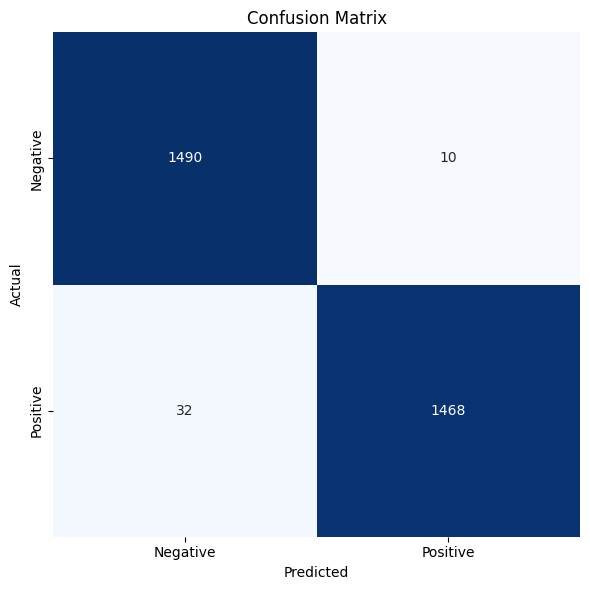

N                     3000.000000
accuracy                 0.986000
precision_positive       0.993234
recall_positive          0.978667
f1_positive              0.985897
TN                    1490.000000
FP                      10.000000
FN                      32.000000
TP                    1468.000000
threshold                0.500000
              precision    recall  f1-score   support

    Negative     0.9790    0.9933    0.9861      1500
    Positive     0.9932    0.9787    0.9859      1500

    accuracy                         0.9860      3000
   macro avg     0.9861    0.9860    0.9860      3000
weighted avg     0.9861    0.9860    0.9860      3000



229

In [ ]:
cnn_prob = cnn_model.predict(cnn_test_ds, verbose=1).reshape(-1)
cnn_truth = cnn_parts['test']['label'].to_numpy(dtype=int)
cnn_pred = (cnn_prob >= CLASSIFICATION_THRESHOLD).astype(int)
assert len(cnn_prob) == 3000
cnf = confusion_matrix(cnn_truth, cnn_pred, labels=[0, 1])

# Your original seaborn heatmap style, with the CORRECT class order.
# In this reconstruction: 0 = Negative and 1 = Positive.
fig, ax = plt.subplots(figsize=(6, 6))
sns.heatmap(cnf, annot=True, fmt='g', vmin=0, cmap='Blues', cbar=False,
            xticklabels=['Negative', 'Positive'],
            yticklabels=['Negative', 'Positive'], ax=ax)
ax.set_xlabel('Predicted')
ax.set_ylabel('Actual')
ax.set_title('Confusion Matrix')
plt.tight_layout()
fig.savefig(RESULTS_DIR/'cnn_test_confusion_matrix.png', dpi=300, bbox_inches='tight')
fig.savefig(RESULTS_DIR/'confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

cnn_metrics = {
    'N': int(len(cnn_truth)),
    'accuracy': float(accuracy_score(cnn_truth, cnn_pred)),
    'precision_positive': float(precision_score(cnn_truth, cnn_pred, zero_division=0)),
    'recall_positive': float(recall_score(cnn_truth, cnn_pred, zero_division=0)),
    'f1_positive': float(f1_score(cnn_truth, cnn_pred, zero_division=0)),
    'TN': int(cnf[0, 0]), 'FP': int(cnf[0, 1]),
    'FN': int(cnf[1, 0]), 'TP': int(cnf[1, 1]),
    'threshold': CLASSIFICATION_THRESHOLD,
}
print(pd.Series(cnn_metrics).to_string())
print(classification_report(cnn_truth, cnn_pred,
                            target_names=['Negative','Positive'],
                            digits=4, zero_division=0))
pd.DataFrame({'id': cnn_parts['test']['id'], 'actual': cnn_truth,
              'prob_crack': cnn_prob, 'predicted': cnn_pred}).to_csv(
              RESULTS_DIR/'cnn_test_predictions.csv', index=False)
(RESULTS_DIR/'cnn_test_metrics.json').write_text(json.dumps(cnn_metrics, indent=2))

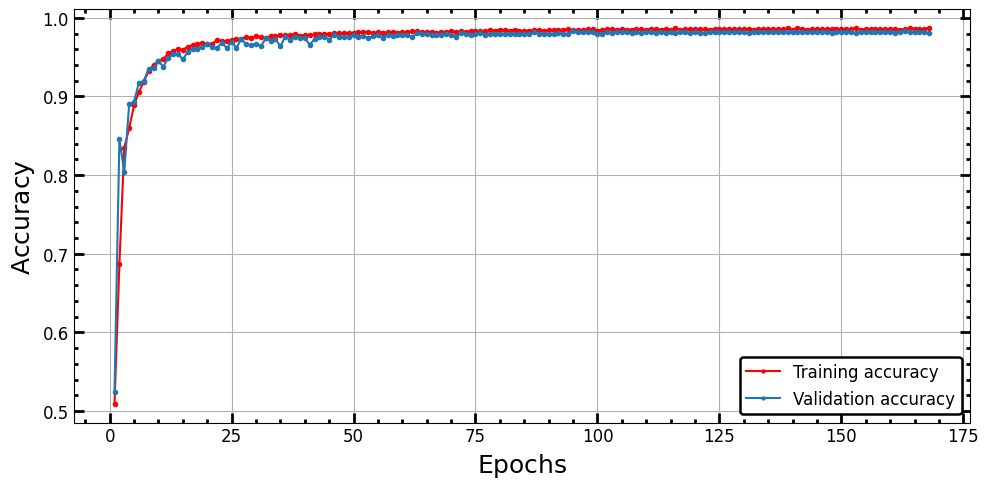

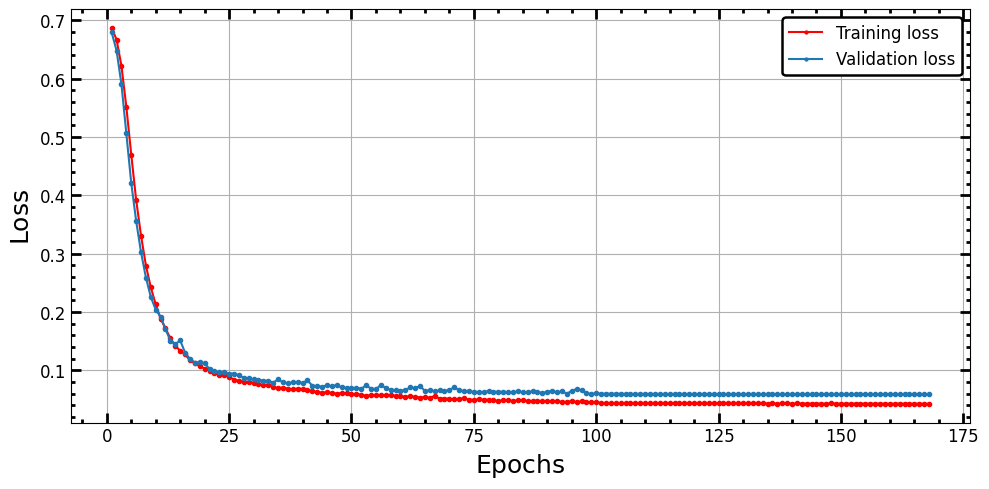

In [ ]:
# Reproduce your CNN plotting conventions from CNN_Classification.ipynb:
# red training series, circular markers, black spines, inward major/minor ticks,
# serif math-style labels, gridded axes, separate 300-dpi PNG files.
from matplotlib.ticker import AutoMinorLocator

cnn_log = RESULTS_DIR/'cnn_training_log.csv'
if cnn_log.exists():
    hist = pd.read_csv(cnn_log)
    epochs = hist['epoch'].to_numpy() + 1

    def original_cnn_plot(train_col, val_col, y_label, save_as, legend_loc):
        fig, ax = plt.subplots(figsize=(10, 5))
        with plt.rc_context({'mathtext.fontset': 'cm'}):
            for side in ['bottom', 'left', 'right', 'top']:
                ax.spines[side].set_color('black')
            ax.plot(epochs, hist[train_col], color='red', marker='o',
                    markersize=3, label='Training ' + y_label.lower())
            ax.plot(epochs, hist[val_col], marker='o', markersize=3,
                    label='Validation ' + y_label.lower())
            leg = ax.legend(loc=legend_loc, fancybox=True, frameon=True,
                            markerscale=0.7, edgecolor='black', prop={'size': 12}, framealpha=1)
            leg.get_frame().set_linewidth(1.8)
            ax.set_xlabel(r'$\mathrm{Epochs}$', size=18)
            ax.set_ylabel(r'$\mathrm{'+y_label+r'}$', size=18)
            ax.xaxis.set_minor_locator(AutoMinorLocator())
            ax.yaxis.set_minor_locator(AutoMinorLocator())
            ax.tick_params(labelsize=12, bottom=True, top=True, left=True, right=True)
            ax.tick_params(axis='x', which='minor', direction='in', top=True, bottom=True)
            ax.tick_params(axis='y', which='minor', direction='in', left=True, right=True)
            ax.tick_params(which='both', width=2)
            ax.tick_params(which='major', length=7, direction='in')
            ax.tick_params(which='minor', length=3, direction='in')
            ax.grid(True)
            fig.tight_layout()
            fig.savefig(RESULTS_DIR/save_as, dpi=300, bbox_inches='tight')
            plt.show()

    original_cnn_plot('accuracy','val_accuracy','Accuracy',
                      'Accuracy_Vs_Epochs.png','lower right')
    original_cnn_plot('loss','val_loss','Loss',
                      'Loss_Vs_Epochs.png','upper right')
else:
    print('CNN training history not found; run CNN training first.')

In [ ]:
def build_espcnn(scale=4):
    inputs=keras.Input(shape=(32,32,3),name='lr_rgb')
    args=dict(padding='same',activation='relu',kernel_initializer='orthogonal')
    x=layers.Conv2D(64,5,name='sr_conv1',**args)(inputs)
    x=layers.Conv2D(64,3,name='sr_conv2',**args)(x)
    x=layers.Conv2D(32,3,name='sr_conv3',**args)(x)
    x=layers.Conv2D(32,3,name='sr_conv4',**args)(x)
    x=layers.Conv2D(3*(scale**2),3,name='sr_conv5',**args)(x)
    outputs=layers.Lambda(lambda t:tf.nn.depth_to_space(t,scale),
                          output_shape=(128,128,3),name='pixel_shuffle')(x)
    return keras.Model(inputs,outputs,name='ESPCNN_83376')

sr_model=build_espcnn()
sr_model.summary()
assert sr_model.count_params()==83376,sr_model.count_params()
assert tuple(sr_model.output_shape[1:])==(128,128,3)

Model: "ESPCNN_83376"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lr_rgb (InputLayer)             │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sr_conv1 (Conv2D)               │ (None, 32, 32, 64)     │         4,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sr_conv2 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sr_conv3 (Conv2D)               │ (None, 32, 32, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sr_conv4 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sr_conv5 (Conv2D)               │ (None, 32, 32, 48)     │        13,872 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pixel_shuffle (Lambda)          │ (None, 128, 128, 3)    │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 83,376 (325.69 KB)

 Trainable params: 83,376 (325.69 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
def tf_psnr(y_true,y_pred): return tf.image.psnr(y_true,y_pred,max_val=1.0)
tf_psnr.__name__='psnr'
sr_model.compile(optimizer=keras.optimizers.Adam(learning_rate=LR_INITIAL),
                 loss='mse',metrics=[tf_psnr])
SR_WEIGHTS=RESULTS_DIR/'espcnn_best.weights.h5'
sr_history=None
if RETRAIN_ESPCNN:
    sr_callbacks=[
        keras.callbacks.ModelCheckpoint(str(SR_WEIGHTS),monitor='val_loss',mode='min',save_best_only=True,save_weights_only=True,verbose=1),
        keras.callbacks.EarlyStopping(monitor='val_loss',min_delta=EARLY_STOP_MIN_DELTA,patience=EARLY_STOP_PATIENCE,mode='min',restore_best_weights=True,verbose=1),
        keras.callbacks.LearningRateScheduler(scheduled_lr),
        keras.callbacks.CSVLogger(str(RESULTS_DIR/'espcnn_training_log.csv')),
        keras.callbacks.BackupAndRestore(backup_dir=str(RESULTS_DIR/'espcnn_training_backup')),
    ]
    start=time.perf_counter()
    sr_history=sr_model.fit(sr_train_ds,validation_data=sr_val_ds,
                            epochs=SR_MAX_EPOCHS,callbacks=sr_callbacks,verbose=1)
    sr_train_seconds=time.perf_counter()-start
    print('ESPCNN training seconds:',round(sr_train_seconds,1))
else:
    if not SR_WEIGHTS.exists(): raise FileNotFoundError(SR_WEIGHTS)
# ModelCheckpoint tracks every validation-loss decrease, independently of
# EarlyStopping(min_delta). The loaded checkpoint may differ from the weights
# restored by EarlyStopping (in the recorded run: epoch 63 vs epoch 43).
sr_model.load_weights(str(SR_WEIGHTS))
print('Loaded best ESPCNN validation weights from:',SR_WEIGHTS)

Epoch 1/2000
199/200 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.1726 - psnr: 8.7771
Epoch 1: val_loss improved from None to 0.01839, saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/espcnn_best.weights.h5

Epoch 1: finished saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/espcnn_best.weights.h5
200/200 ━━━━━━━━━━━━━━━━━━━━ 15s 26ms/step - loss: 0.0912 - psnr: 12.1962 - val_loss: 0.0184 - val_psnr: 17.4640 - learning_rate: 1.0000e-04
Epoch 2/2000
192/200 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0162 - psnr: 18.0268
Epoch 2: val_loss improved from 0.01839 to 0.01286, saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/espcnn_best.weights.h5

Epoch 2: finished saving model to /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results/espcnn_best.weights.h5
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0148 - psnr: 18.4271 - val_loss: 0.0129 - val_psnr: 19.0186 - learning_rate: 1.0000e-04
Epoch 3/2000
194/200 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/ste

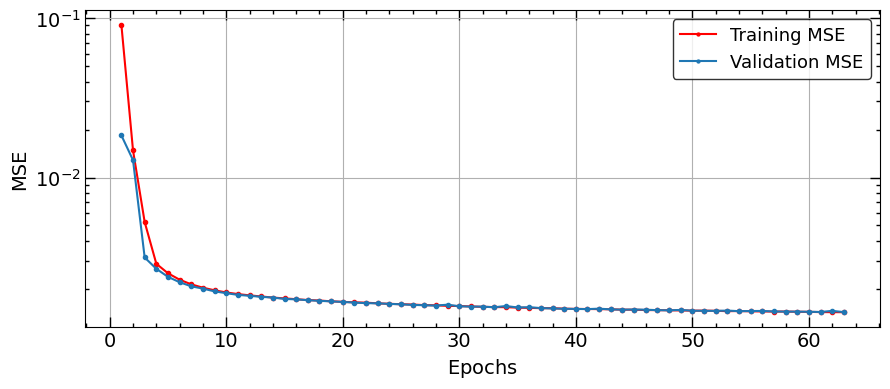

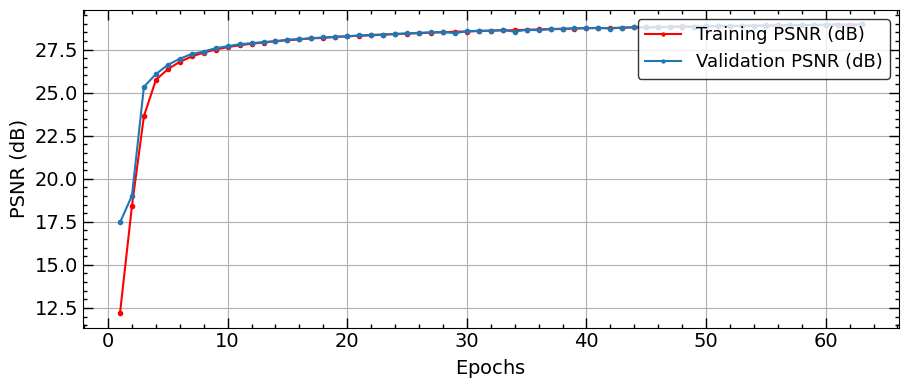

In [ ]:
# Reproduce your Efficiennt subpixel.ipynb loss figure styling;
# supplement it with matching PSNR figure for the submitted paper.
from matplotlib.ticker import AutoMinorLocator, LogLocator

sr_log = RESULTS_DIR/'espcnn_training_log.csv'
if sr_log.exists():
    hist = pd.read_csv(sr_log)
    epochs = hist['epoch'].to_numpy() + 1

    def original_espcnn_plot(train_col, val_col, ylabel, filename, use_log=False):
        fig, ax = plt.subplots(figsize=(9, 4))
        with plt.rc_context({'mathtext.fontset': 'cm'}):
            for side in ['bottom', 'left', 'right', 'top']:
                ax.spines[side].set_color('black')
            ax.plot(epochs, hist[train_col], color='red', marker='o',
                    markersize=3, label='Training ' + ylabel)
            ax.plot(epochs, hist[val_col], marker='o', markersize=3,
                    label='Validation ' + ylabel)
            leg = ax.legend(loc='upper right', bbox_to_anchor=(1,1),
                            fancybox=True, frameon=True, markerscale=0.7,
                            edgecolor='black', prop={'size': 13})
            leg.get_frame().set_linewidth(1)
            ax.tick_params(labelsize=14)
            ax.set_xlabel(r'$\mathrm{Epochs}$', size=14)
            ax.set_ylabel(ylabel, size=14)
            if use_log:
                ax.set_yscale('log')
                ax.yaxis.set_minor_locator(LogLocator(subs='all'))
            else:
                ax.yaxis.set_minor_locator(AutoMinorLocator())
            ax.xaxis.set_minor_locator(AutoMinorLocator())
            ax.tick_params(bottom=True, top=True, left=True, right=True)
            ax.tick_params(axis='x', which='minor', direction='in', top=True, bottom=True)
            ax.tick_params(axis='y', which='minor', direction='in', left=True, right=True)
            ax.tick_params(which='both', width=1)
            ax.tick_params(which='major', length=7, direction='in')
            ax.tick_params(which='minor', length=3, direction='in')
            ax.grid(True)
            fig.tight_layout()
            fig.savefig(RESULTS_DIR/filename, dpi=300, bbox_inches='tight')
            plt.show()

    original_espcnn_plot('loss','val_loss','MSE',
                         'ESPCNN_MSE_Vs_Epochs.png', use_log=True)
    if 'psnr' in hist.columns and 'val_psnr' in hist.columns:
        original_espcnn_plot('psnr','val_psnr','PSNR (dB)',
                             'ESPCNN_PSNR_Vs_Epochs.png')
else:
    print('ESPCNN training history not found; run ESPCNN training first.')

In [ ]:
LR_test,HR_test,SR_test=[],[],[]
for batch_lr,batch_hr in tqdm(sr_test_ds,desc='ESPCNN test inference'):
    preds=sr_model(batch_lr,training=False)
    LR_test.append(batch_lr.numpy());HR_test.append(batch_hr.numpy())
    SR_test.append(np.clip(preds.numpy(),0.,1.))
LR_test=np.concatenate(LR_test).astype(np.float32)
HR_test=np.concatenate(HR_test).astype(np.float32)
SR_test=np.concatenate(SR_test).astype(np.float32)
assert len(LR_test)==len(HR_test)==len(SR_test)==1000

def bicubic_upscale(lr):
    rgb=np.uint8(np.clip(np.rint(lr*255),0,255))
    return np.asarray(Image.fromarray(rgb,'RGB').resize((128,128),Image.Resampling.BICUBIC),dtype=np.float32)/255.0
BIC_test=np.stack([bicubic_upscale(lr) for lr in tqdm(LR_test,desc='Bicubic baseline')])

def image_scores(gt,pred):
    return {'PSNR':float(peak_signal_noise_ratio(gt,pred,data_range=1.0)),
            'SSIM':float(structural_similarity(gt,pred,data_range=1.0,channel_axis=-1)),
            'MSE':float(np.mean((gt-pred)**2))}
records=[]
for i,(gt,sr,bic) in enumerate(zip(HR_test,SR_test,BIC_test)):
    records.append({'id':sr_parts['test'].iloc[i]['id'],
                    **{'ESPCNN_'+k:v for k,v in image_scores(gt,sr).items()},
                    **{'Bicubic_'+k:v for k,v in image_scores(gt,bic).items()}})
sr_scores=pd.DataFrame(records)
print(sr_scores.drop(columns='id').mean(numeric_only=True))

ESPCNN test inference:   0%|          | 0/63 [00:00<?, ?it/s]

Bicubic baseline:   0%|          | 0/1000 [00:00<?, ?it/s]

/tmp/ipykernel_37404/1884792061.py:13: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return np.asarray(Image.fromarray(rgb,'RGB').resize((128,128),Image.Resampling.BICUBIC),dtype=np.float32)/255.0


ESPCNN_PSNR     28.938209
ESPCNN_SSIM      0.724101
ESPCNN_MSE       0.001440
Bicubic_PSNR    28.152799
Bicubic_SSIM     0.710760
Bicubic_MSE      0.001714
dtype: float64


In [ ]:
if RUN_LPIPS:
    try:
        import torch, lpips
        lpips_net=lpips.LPIPS(net='vgg').eval().to('cpu')
        def compute_lpips(truth,pred,batch_size=8):
            scores=[]
            with torch.no_grad():
                for i in tqdm(range(0,len(truth),batch_size),desc='LPIPS'):
                    a=torch.from_numpy(truth[i:i+batch_size]).permute(0,3,1,2).float()*2-1
                    b=torch.from_numpy(pred[i:i+batch_size]).permute(0,3,1,2).float()*2-1
                    scores.extend(lpips_net(a,b).flatten().cpu().numpy().astype(float).tolist())
            return scores
        sr_scores['ESPCNN_LPIPS']=compute_lpips(HR_test,SR_test)
        sr_scores['Bicubic_LPIPS']=compute_lpips(HR_test,BIC_test)
    except Exception as exc:
        print('LPIPS unavailable; no LPIPS values will be reported:',type(exc).__name__,str(exc)[:250])
        sr_scores['ESPCNN_LPIPS']=np.nan
        sr_scores['Bicubic_LPIPS']=np.nan
else:
    sr_scores['ESPCNN_LPIPS']=np.nan
    sr_scores['Bicubic_LPIPS']=np.nan

sr_scores.to_csv(RESULTS_DIR/'espcnn_test_per_image_metrics.csv',index=False)
sr_summary=pd.DataFrame({
    'Method':['Bicubic interpolation','ESPCNN'],
    'PSNR_dB':[sr_scores['Bicubic_PSNR'].mean(),sr_scores['ESPCNN_PSNR'].mean()],
    'SSIM':[sr_scores['Bicubic_SSIM'].mean(),sr_scores['ESPCNN_SSIM'].mean()],
    'LPIPS':[sr_scores['Bicubic_LPIPS'].mean(),sr_scores['ESPCNN_LPIPS'].mean()],
})
sr_summary.to_csv(RESULTS_DIR/'espcnn_table3_reconstruction.csv',index=False)
print(sr_summary.to_string(index=False,float_format=lambda x:f'{x:.4f}'))
print('\nPreviously submitted Table III (not target values): bicubic 28.00/0.86/0.41; ESPCNN 29.00/0.88/0.39')

Setting up [LPIPS] perceptual loss: trunk [vgg], v[0.1], spatial [off]


/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=VGG16_Weights.IMAGENET1K_V1`. You can also use `weights=VGG16_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Loading model from: /usr/local/lib/python3.13/dist-packages/lpips/weights/v0.1/vgg.pth


LPIPS:   0%|          | 0/125 [00:00<?, ?it/s]

LPIPS:   0%|          | 0/125 [00:00<?, ?it/s]

               Method  PSNR_dB   SSIM  LPIPS
Bicubic interpolation  28.1528 0.7108 0.4115
               ESPCNN  28.9382 0.7241 0.3983

Previously submitted Table III (not target values): bicubic 28.00/0.86/0.41; ESPCNN 29.00/0.88/0.39


In [ ]:
joint_data_ds=cnn_ds(joint_df,training=False,batch_size=32)
joint_probs=cnn_model.predict(joint_data_ds,verbose=1).reshape(-1)
joint_df=joint_df.copy()
joint_df['prob_crack']=joint_probs
joint_df['cnn_predicted_positive']=(joint_probs>=CLASSIFICATION_THRESHOLD)
joint_truth=joint_df['label'].to_numpy(dtype=int)
joint_pred=joint_df['cnn_predicted_positive'].astype(int).to_numpy()
joint_cm=confusion_matrix(joint_truth,joint_pred,labels=[0,1])

# Actually execute ESPCNN for the predicted-positive images (not merely count them).
routed_df=joint_df[joint_df.cnn_predicted_positive].copy().reset_index(drop=True)
def routed_image_ds(df,batch_size=SR_BATCH_SIZE):
    ds=tf.data.Dataset.from_tensor_slices(df['lr_path'].astype(str).to_numpy())
    return ds.map(read_lr,num_parallel_calls=AUTOTUNE).batch(batch_size).prefetch(AUTOTUNE)
if len(routed_df):
    routed_predictions=sr_model.predict(routed_image_ds(routed_df),verbose=1)
    print('Actual ESPCNN outputs shape:',routed_predictions.shape)
else:
    routed_predictions=np.empty((0,128,128,3),dtype=np.float32)

joint_metrics={
    'N':len(joint_df),
    'ground_truth_positive':int((joint_truth==1).sum()),
    'ground_truth_negative':int((joint_truth==0).sum()),
    'forwarded_to_ESPCNN':int(len(routed_df)),
    'bypassed_ESPCNN':int((~joint_df.cnn_predicted_positive).sum()),
    'TP':int(joint_cm[1,1]), 'FN':int(joint_cm[1,0]),
    'FP':int(joint_cm[0,1]), 'TN':int(joint_cm[0,0]),
    'threshold':CLASSIFICATION_THRESHOLD,
}
print('Combined pipeline, independent joint test:')
print(pd.Series(joint_metrics).to_string())
(RESULTS_DIR/'joint_pipeline_metrics.json').write_text(json.dumps(joint_metrics,indent=2))
joint_df.to_csv(RESULTS_DIR/'joint_pipeline_routing.csv',index=False)

# Comparisons on *detected* true-positive images only, all held-out for both models.
detected_positive_ids=set(joint_df.loc[(joint_df.label==1)&(joint_df.cnn_predicted_positive),'id'])
quality_subset=sr_scores[sr_scores.id.isin(detected_positive_ids)]
print('\nESPCNN quality on correctly routed positives, N=',len(quality_subset))
if len(quality_subset):
    print(quality_subset.drop(columns='id').mean(numeric_only=True).to_string())
print('WARNING: quality on routed positives alone excludes missed cracks and is not an end-to-end detection score.')

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step
62/62 ━━━━━━━━━━━━━━━━━━━━ 3s 48ms/step
Actual ESPCNN outputs shape: (983, 128, 128, 3)
Combined pipeline, independent joint test:
N                        2000.0
ground_truth_positive    1000.0
ground_truth_negative    1000.0
forwarded_to_ESPCNN       983.0
bypassed_ESPCNN          1017.0
TP                        976.0
FN                         24.0
FP                          7.0
TN                        993.0
threshold                   0.5

ESPCNN quality on correctly routed positives, N= 976
ESPCNN_PSNR      28.886090
ESPCNN_SSIM       0.722808
ESPCNN_MSE        0.001454
Bicubic_PSNR     28.094581
Bicubic_SSIM      0.709468
Bicubic_MSE       0.001732
ESPCNN_LPIPS      0.397782
Bicubic_LPIPS     0.411032


In [ ]:
def mac_table(model):
    rows=[]
    for layer in model.layers:
        if isinstance(layer,layers.Conv2D):
            h,w,c_out=map(int,layer.output.shape[1:4])
            c_in=int(layer.input.shape[-1]);kh,kw=layer.kernel_size
            mac=h*w*c_out*c_in*kh*kw
            rows.append({'network':model.name,'layer':layer.name,'type':'Conv2D','output_shape':str(tuple(layer.output.shape[1:])), 'MACs':mac})
        elif isinstance(layer,layers.Dense):
            mac=int(layer.input.shape[-1])*int(layer.units)
            rows.append({'network':model.name,'layer':layer.name,'type':'Dense','output_shape':str(tuple(layer.output.shape[1:])), 'MACs':mac})
    return pd.DataFrame(rows)

In [ ]:

# ======================================================
# 10,000-IMAGE GPU INFERENCE BENCHMARK
# Baseline: ESPCNN on ALL images
# Proposed: CNN + selective ESPCNN
# ======================================================

from pathlib import Path
import time
import json
import numpy as np
import pandas as pd
import tensorflow as tf

RESULTS_DIR = Path(
    '/content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results'
)

BENCHMARK_BATCH_SIZE = 32
BENCHMARK_REPEATS = 7
CRACK_THRESHOLD = 0.5

assert tf.config.list_physical_devices('GPU'), \
    "Enable a GPU runtime first."

# ------------------------------------------
# 1. LOAD BEST SAVED MODEL WEIGHTS
# ------------------------------------------

cnn_model.load_weights(
    str(RESULTS_DIR / 'cnn_best.weights.h5')
)

sr_model.load_weights(
    str(RESULTS_DIR / 'espcnn_best.weights.h5')
)

print("Both models loaded successfully.")

# ------------------------------------------
# 2. LOAD ALL 10,000 SELECTED IMAGE PATHS
# ------------------------------------------

benchmark_df = pd.read_csv(
    RESULTS_DIR / 'selected_image_manifest.csv'
)

assert len(benchmark_df) == 10000

assert benchmark_df['label'].value_counts().to_dict() == {
    0: 5000,
    1: 5000
}

benchmark_df = benchmark_df.sample(
    frac=1, random_state=42
).reset_index(drop=True)

paths = benchmark_df['lr_path'].astype(str).to_numpy()

missing = [p for p in paths if not Path(p).is_file()]

if missing:
    raise FileNotFoundError(
        "Resized images missing. Rerun dataset extraction "
        "and image preparation cells."
    )

# ------------------------------------------
# 3. DECODE IMAGES BEFORE TIMING
# ------------------------------------------

def decode_lr(path):
    img = tf.io.decode_jpeg(
        tf.io.read_file(path),
        channels=3
    )
    img = tf.image.convert_image_dtype(
        img, tf.float32
    )
    return tf.ensure_shape(img, [32, 32, 3])

dataset = (
    tf.data.Dataset.from_tensor_slices(paths)
    .map(
        decode_lr,
        num_parallel_calls=tf.data.AUTOTUNE
    )
    .batch(256)
    .prefetch(tf.data.AUTOTUNE)
)

X_10000 = np.concatenate(
    [batch.numpy() for batch in dataset],
    axis=0
)

assert X_10000.shape == (10000, 32, 32, 3)

print("Images cached:", len(X_10000))

# ------------------------------------------
# 4. OPTIMIZED INFERENCE FUNCTIONS
# ------------------------------------------

input_signature = [
    tf.TensorSpec(
        shape=(None, 32, 32, 3),
        dtype=tf.float32
    )
]

@tf.function(input_signature=input_signature)
def cnn_forward(x):
    return cnn_model(x, training=False)

@tf.function(input_signature=input_signature)
def espcnn_forward(x):
    return sr_model(x, training=False)

# ------------------------------------------
# 5. BASELINE: ESPCNN ON ALL IMAGES
# ------------------------------------------

def run_all_image_espcnn():

    for start in range(
        0, len(X_10000), BENCHMARK_BATCH_SIZE
    ):

        batch = X_10000[
            start:start + BENCHMARK_BATCH_SIZE
        ]

        output = espcnn_forward(
            tf.convert_to_tensor(batch)
        )

        _ = output.numpy()  # GPU synchronization

    return len(X_10000)

# ------------------------------------------
# 6. PROPOSED: CNN + SELECTIVE ESPCNN
# ------------------------------------------

def run_cnn_selective_espcnn():

    masks = []

    # First: CNN on all 10,000 images
    for start in range(
        0, len(X_10000), BENCHMARK_BATCH_SIZE
    ):

        batch = X_10000[
            start:start + BENCHMARK_BATCH_SIZE
        ]

        probabilities = cnn_forward(
            tf.convert_to_tensor(batch)
        ).numpy().reshape(-1)

        masks.append(
            probabilities >= CRACK_THRESHOLD
        )

    selected_mask = np.concatenate(masks)

    # Collect predicted-positive images
    selected_images = X_10000[selected_mask]

    # Second: ESPCNN on selected images only
    for start in range(
        0, len(selected_images), BENCHMARK_BATCH_SIZE
    ):

        batch = selected_images[
            start:start + BENCHMARK_BATCH_SIZE
        ]

        output = espcnn_forward(
            tf.convert_to_tensor(batch)
        )

        _ = output.numpy()

    return len(selected_images)

# ------------------------------------------
# 7. GPU WARMUP
# ------------------------------------------

print("\nWarming up GPU...")

for _ in range(2):
    run_all_image_espcnn()
    n_forwarded = run_cnn_selective_espcnn()

print("Forwarded to ESPCNN:", n_forwarded)
print("Bypassed ESPCNN:", 10000 - n_forwarded)

# ------------------------------------------
# 8. ACTUAL GPU TIMING
# ------------------------------------------

timing_records = []

for trial in range(1, BENCHMARK_REPEATS + 1):

    methods = [
        ("ESPCNN_all", run_all_image_espcnn),
        ("CNN_selective_ESPCNN", run_cnn_selective_espcnn)
    ]

    # Alternate execution order
    if trial % 2 == 0:
        methods.reverse()

    for name, method in methods:

        start = time.perf_counter()

        processed = method()

        elapsed = time.perf_counter() - start

        if name == "CNN_selective_ESPCNN":
            assert processed == n_forwarded

        timing_records.append({
            "trial": trial,
            "strategy": name,
            "time_seconds": elapsed,
            "espcnn_images": processed
        })

        print(
            f"Trial {trial} | {name} | "
            f"{elapsed:.4f} seconds"
        )

# ------------------------------------------
# 9. COMPUTE RESULTS
# ------------------------------------------

timing_df = pd.DataFrame(timing_records)

median_times = (
    timing_df.groupby("strategy")["time_seconds"]
    .median()
)

time_all = float(median_times["ESPCNN_all"])
time_selective = float(
    median_times["CNN_selective_ESPCNN"]
)

time_saved = time_all - time_selective

time_reduction = (
    (time_saved / time_all) * 100
)

# MACs per image from our existing architectures
CNN_MACS = 4_002_528
ESPCNN_MACS = 85_131_264

all_macs = 10000 * ESPCNN_MACS

selective_macs = (
    10000 * CNN_MACS
    + n_forwarded * ESPCNN_MACS
)

mac_reduction = (
    1 - selective_macs / all_macs
) * 100

# ------------------------------------------
# 10. DISPLAY RESULTS
# ------------------------------------------

print("\n" + "=" * 55)
print("GPU INFERENCE RESULTS - 10,000 IMAGES")
print("=" * 55)

print(f"Total images:              {10000:,}")
print(f"Forwarded to ESPCNN:       {n_forwarded:,}")
print(f"Bypassed ESPCNN:           {10000-n_forwarded:,}")

print(f"\nESPCNN on all images:      {time_all:.4f} s")
print(f"CNN + selective ESPCNN:    {time_selective:.4f} s")
print(f"GPU time saved:            {time_saved:.4f} s")
print(f"GPU time reduction:        {time_reduction:.2f}%")

print(f"\nBaseline MACs:             {all_macs/1e9:.3f} billion")
print(f"Selective MACs:            {selective_macs/1e9:.3f} billion")
print(f"MAC reduction:             {mac_reduction:.2f}%")

# ------------------------------------------
# 11. SAVE RESULTS TO GOOGLE DRIVE
# ------------------------------------------

timing_df.to_csv(
    RESULTS_DIR / "inference_timing_10000_trials.csv",
    index=False
)

summary = {
    "total_images": 10000,
    "forwarded_to_ESPCNN": int(n_forwarded),
    "bypassed_ESPCNN": int(10000 - n_forwarded),
    "batch_size": BENCHMARK_BATCH_SIZE,
    "repetitions": BENCHMARK_REPEATS,
    "baseline_median_seconds": time_all,
    "selective_median_seconds": time_selective,
    "time_saved_seconds": time_saved,
    "time_reduction_percent": time_reduction,
    "baseline_MACs": int(all_macs),
    "selective_MACs": int(selective_macs),
    "MAC_reduction_percent": mac_reduction,
    "benchmark_note": (
        "Runtime benchmark on all 10,000 selected patches, "
        "including training, validation, and test images. "
        "Image decoding excluded from timing."
    )
}

with open(
    RESULTS_DIR / "inference_timing_10000_summary.json",
    "w"
) as f:
    json.dump(summary, f, indent=2)

print("\nBenchmark results saved successfully.")


Both models loaded successfully.
Images cached: 10000

Warming up GPU...
Forwarded to ESPCNN: 4927
Bypassed ESPCNN: 5073
Trial 1 | ESPCNN_all | 2.3306 seconds
Trial 1 | CNN_selective_ESPCNN | 2.1837 seconds
Trial 2 | CNN_selective_ESPCNN | 2.7305 seconds
Trial 2 | ESPCNN_all | 1.6333 seconds
Trial 3 | ESPCNN_all | 1.4321 seconds
Trial 3 | CNN_selective_ESPCNN | 1.1915 seconds
Trial 4 | CNN_selective_ESPCNN | 1.2160 seconds
Trial 4 | ESPCNN_all | 1.4010 seconds
Trial 5 | ESPCNN_all | 1.3932 seconds
Trial 5 | CNN_selective_ESPCNN | 1.2054 seconds
Trial 6 | CNN_selective_ESPCNN | 1.2313 seconds
Trial 6 | ESPCNN_all | 1.5261 seconds
Trial 7 | ESPCNN_all | 1.5842 seconds
Trial 7 | CNN_selective_ESPCNN | 1.4751 seconds

GPU INFERENCE RESULTS - 10,000 IMAGES
Total images:              10,000
Forwarded to ESPCNN:       4,927
Bypassed ESPCNN:           5,073

ESPCNN on all images:      1.5261 s
CNN + selective ESPCNN:    1.2313 s
GPU time saved:            0.2948 s
GPU time reduction:        19

In [ ]:

# ======================================================
# FINAL EXPERIMENT SUMMARY
# CNN + ESPCNN + 10,000-IMAGE GPU BENCHMARK
# ======================================================

import json
import pandas as pd
import numpy as np
from pathlib import Path

# ==========================================
# 1. ORIGINAL EXPERIMENT RESULTS
# ==========================================

print('=== CNN TEST (3,000 IMAGES) ===')
print(pd.Series(cnn_metrics).to_string())

print('\n=== ESPCNN TEST (1,000 IMAGES) ===')
print(
    sr_summary.to_string(
        index=False,
        float_format=lambda n: f'{n:.4f}'
    )
)

print('\n=== JOINT PIPELINE (2,000 IMAGES) ===')
print(pd.Series(joint_metrics).to_string())



# ==========================================
# 2. LOAD NEW 10,000-IMAGE BENCHMARK
# ==========================================

benchmark_path = (
    RESULTS_DIR / 'inference_timing_10000_summary.json'
)

if not benchmark_path.exists():
    raise FileNotFoundError(
        f'10,000-image benchmark not found: {benchmark_path}'
    )

with open(benchmark_path, 'r') as f:
    benchmark_10000 = json.load(f)

print('\n' + '=' * 60)
print('=== GPU BENCHMARK (10,000 IMAGES) ===')
print('=' * 60)

print(
    'Total images:',
    benchmark_10000['total_images']
)

print(
    'Forwarded to ESPCNN:',
    benchmark_10000['forwarded_to_ESPCNN']
)

print(
    'Bypassed ESPCNN:',
    benchmark_10000['bypassed_ESPCNN']
)

print(
    '\nESPCNN on all images:',
    f"{benchmark_10000['baseline_median_seconds']:.4f} s"
)

print(
    'CNN + selective ESPCNN:',
    f"{benchmark_10000['selective_median_seconds']:.4f} s"
)

print(
    'GPU time reduction:',
    f"{benchmark_10000['time_reduction_percent']:.2f}%"
)

print(
    'MAC reduction:',
    f"{benchmark_10000['MAC_reduction_percent']:.2f}%"
)


# ==========================================
# 3. COMBINE ALL EXPERIMENT RESULTS
# ==========================================

report = {

    'experiment_type': (
        'CNN crack screening and selective ESPCNN '
        'super-resolution'
    ),

    'seed': SEED,

    'cnn_train_val_test': [
        4900, 2100, 3000
    ],

    'espcnn_train_val_test': [
        3200, 800, 1000
    ],

    'joint_test_n': 2000,

    'models': {
        'cnn_parameters': int(cnn_model.count_params()),
        'espcnn_parameters': int(sr_model.count_params())
    },

    'cnn_metrics': cnn_metrics,

    'espcnn_summary': [
        {
            key: (
                None if pd.isna(value) else value
            )
            for key, value in row.items()
        }
        for row in sr_summary.to_dict(
            orient='records'
        )
    ],

    'joint_pipeline': joint_metrics,

    # 10,000-image inference benchmark (timing + MAC estimates)
    'benchmark_10000': benchmark_10000,

    'limitations': [
        'Original source-photo groups not verified.',
        'Patch-level splits may contain images from '
        'the same original photograph.',
        'No downstream detector was evaluated.',
        'Low-resolution images were generated '
        'synthetically by bicubic resizing.',
        'The 10,000-image timing workload includes '
        'training, validation, and test images.'
    ]
}


# ==========================================
# 4. SAVE COMPLETE RESULTS
# ==========================================

output_path = (
    RESULTS_DIR / 'FULL_EXPERIMENT_RESULTS.json'
)

def json_converter(obj):
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, pd.Series):
        return obj.to_dict()
    raise TypeError(f'Not JSON serializable: {type(obj)}')

output_path.write_text(
    json.dumps(
        report,
        indent=2,
        allow_nan=False,
        default=json_converter
    )
)

print('\n' + '=' * 60)
print('ALL EXPERIMENT RESULTS SAVED')
print('=' * 60)

print('Results directory:', RESULTS_DIR)
print('Summary file:', output_path)
print('10,000-image GPU benchmark included.')


In [ ]:
archive_target=RESULTS_DIR.parent/'CCWC2027_CNN_ESPCNN_Results.zip'
shutil.make_archive(str(archive_target.with_suffix('')),'zip',root_dir=RESULTS_DIR)
print('Results ZIP:',archive_target)
print('Size (MB):',round(archive_target.stat().st_size/1e6,2))

Results ZIP: /content/drive/MyDrive/CCWC2027_CNN_ESPCNN_Results.zip
Size (MB): 243.92
